# Generate source-level connectomes from tractogrames

In this tutorial, we show how to generate a source-level connectome from an individual subject's tractogram. The connectome is used to define its connectome spectrum transform, which is an essential part of the CSET method. <br>

Tractography is a 3D modeling technique that visualizes nerve tracts based on data from diffusion MRI. The output is typically displayed as two- or three-dimensional images known as tractograms, which illustrate the physical connections between brain regions. These connections can be represented as a graph, called a **structural connectome**, where nodes correspond to brain regions and edges represent structural links. In our context, brain regions are modeled as dipoles in the source model. To determine which dipoles are connected, we apply a nearest-neighbor algorithm to the endpoints of the nerve tracts. Each tract thereby identifies a connection between specific dipoles. <br>

In more detail, the following steps are applied:
1. **Filter out non-credible tracts** to eliminate spurious or anatomically implausible connections.
2. **Associate tract endpoints with dipoles** using a nearest-neighbor algorithm.
3. **Smooth the results** to generate a high-resolution connectome.
4. **Add local neighbor connections** to account for interactions within gray matter.
5. **Assign informative weights** to the connections based on tract-specific properties.

(J'aimerai bien un petit shéma la)

## 📦 Imports

In [2]:
import mindmap as mm
import scipy as sp
import numpy as np
import pygsp
import nibabel as nib
import pyvista as pv

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `parc`: Parcellation
- `ctx`: Cortical mask
- `t12diff`: Transformation (T1 -> diffusion)
- `tracto`: Tractogram
- `cras`: Translation (T1 -> RAS)
- `src`: Source space (after forward solution)

🎚️ **<font color=pink>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: subject id

In [3]:
################## Parameters ####################
fconfig = "../../papers/simf/configuration.yml"
sub     = 1
##################################################

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "src1000", "cras", "tracto", "t12diff", "parc", "ctx")
data["src"] = data["src1000"]

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- tracto
- ctx
- src1000
- t12diff
- parc
- cras
Missing objects:


In [4]:
# utility
def print_sc_summary(sc):
    """
    Print various interesting information about the connectome matrix.
    """
    # compute number of connections per node
    connections_per_node = (sc > 0).sum(axis=1)

    N = len(sc)
    E = np.sum(connections_per_node)/2

    print(f"Number of nodes: {N}")
    print(f"Total number of connections: {E} (sparsity = {2*E/(N*N-N):.3}%)")
    print(f"Minimum (non-zero) weight: {sc[sc>0].min()}")
    print(f"Maximum weight: {sc.max()}")
    print(f"Number of isolated nodes: {np.sum(connections_per_node==0)} (ratio = {np.sum(connections_per_node==0)/N*100:.3})%")

## 1. Filter out non-credible tracts

To associate streamline endpoints with dipoles, we first ensure that the streamline space and the dipole space (RAS) are properly aligned. We then discard streamlines whose endpoints fall outside the cortex, based on the assumption that tracts connect cortico-cortically. Finally, each remaining streamline endpoint is matched to its nearest dipole, enabling the construction of the structural connectome.

📥 **<font color=pink>Inputs</font>**

- `tracto`: Tractogram – contains the endpoints of streamlines (tracts).
- `src`: Source space – provides the positions of dipoles.
- `t12diff`: Transformation matrix – aligns MNI space with the streamline (diffusion) space.
- `cras`: Translation vector – aligns MNI space with the dipole (RAS) space.
- `ctx`: Cortical mask – used to filter out streamlines that do not terminate in cortical regions.
- `parc`: Parcellation – used to construct a region-based connectome and to validate the anatomical plausibility of connections`

📥 **<font color=pink>Outputs</font>**
- `sc`: Structural connectome

#### ⚙️ **<font color=green>Align sources and streamlines </font>**

In [5]:
# dipoles
pos = mm.utils.get_src_position(data["src"])
pos = pos*1000 + data["cras"] - data["t12diff"][:3,3]  # in [mm], aligns dipoles to tract endpoints

# dipole labeling (to order dipoles according to atlas brain regions)
labels = data["parc"].label_points(pos, id=True)
idx    = np.argsort(labels)                         

# streamline endpoints
voxel_size = data["tracto"].header["voxel_sizes"].reshape(1,-1)
starts     = np.array([stream[0] for stream in data["tracto"].streamlines]) / voxel_size
ends       = np.array([stream[-1] for stream in data["tracto"].streamlines]) / voxel_size
lengths    = np.array([mm.utils.compute_streamline_length(stream) for stream in data["tracto"].streamlines])        # to use as weights


#### ⚙️ **<font color=green>Make region-based connectome</font>**

Number of nodes: 473
Total number of connections: 4399.0 (sparsity = 0.0394%)
Minimum (non-zero) weight: 4.999990940093994
Maximum weight: 147.99996948242188
Number of isolated nodes: 0 (ratio = 0.0)%


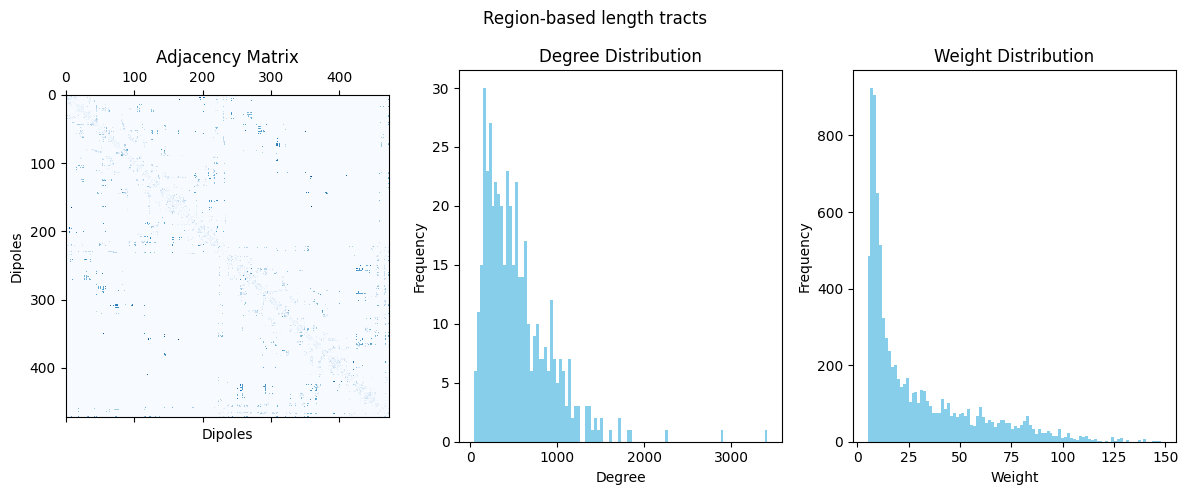

In [8]:
# label streamlines
start_labels = data["parc"].label_points(starts, id=True)
end_labels   = data["parc"].label_points(ends, id=True)

# dismiss streamlines having endpoints outside any region
dismiss      = (start_labels==0) | (end_labels==0)
start_labels = start_labels[~dismiss]
end_labels   = end_labels[~dismiss]

# connectome with weights corresponding to lengths
conn_lengths = mm.utils.build_connectivity_matrix(
    start_labels-1, 
    end_labels-1, 
    data["parc"].n_regions, 
    w = lengths[~dismiss],
)

# connectome with weights corresponding to number of fibers
conn_weights = mm.utils.build_connectivity_matrix(
    start_labels-1,
    end_labels-1,
    data["parc"].n_regions,
    w = None
)

# visualize #
print_sc_summary(conn_lengths)
mm.viz.plot_connectome(conn_lengths, nonzero=True, name="Region-based length tracts")

Number of nodes: 473
Total number of connections: 4399.0 (sparsity = 0.0394%)
Minimum (non-zero) weight: 1.0
Maximum weight: 442.0
Number of isolated nodes: 0 (ratio = 0.0)%


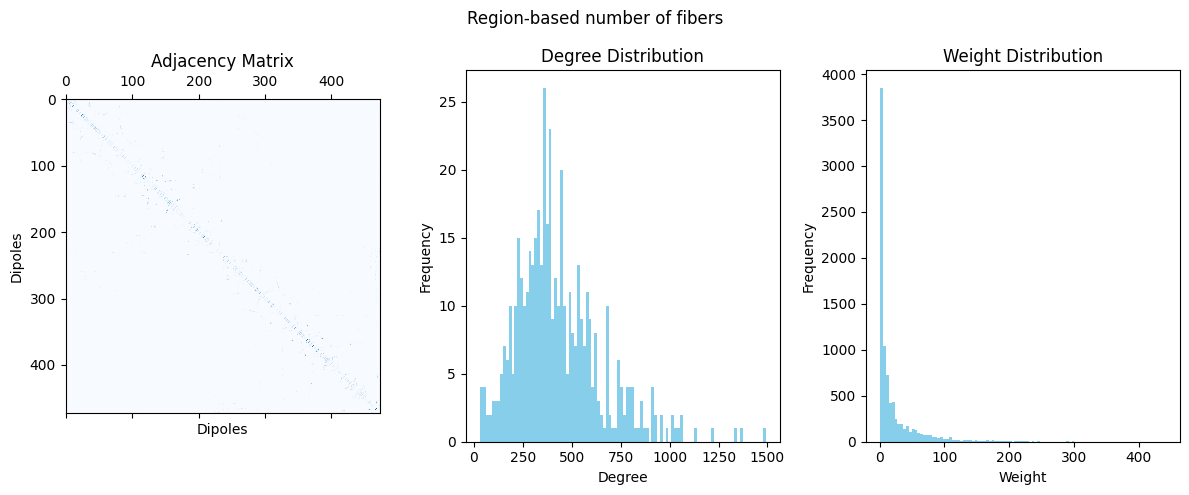

In [9]:
# visualize #
print_sc_summary(conn_weights)
mm.viz.plot_connectome(conn_weights, nonzero=True, name="Region-based number of fibers")

#### 💾 Save region-based connectome

In [9]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from tractography for subject: {sub}")
np.save(folder/f"{sub}_sc-parc-lengths.npy", conn_lengths)
np.save(folder/f"{sub}_sc-parc-weights.npy", conn_weights)

Saving SC from tractography for subject: vepcon_sub-10


#### ⚙️ **<font color=green>Delete streamlines having endpoints outside of cortical regions</font>**

In [10]:
inv_affine = np.linalg.inv(data["ctx"].affine)
volume     = data["ctx"].get_fdata()

retain = []
for points in [starts, ends]:
    vox  = nib.affines.apply_affine(inv_affine, points)         # transfer points to T1 voxel ids
    vox  = np.round(vox).astype(int)
    mask = volume[vox[:,0], vox[:,1], vox[:,2]].astype(bool)    # retrieve ctx mask value at voxel position

    retain.append(mask)

retain = retain[0] * retain[1]                      # retain is True if start and end point are in the cortex.
print(f"Quantity of streammlines removed: {np.sum(~retain)/len(retain)*100:.3}%")

dismiss_s = starts[~retain]
dismiss_e = ends[~retain]

starts  = starts[retain]
ends    = ends[retain]

lengths = lengths[retain]

Quantity of streammlines removed: 30.4%


🌟 **Visualize alignment**

In [11]:
# points
src       = pv.PolyData(nib.affines.apply_affine(inv_affine, pos))
retained  = pv.PolyData(nib.affines.apply_affine(inv_affine, np.vstack([starts, ends])))
dismissed = pv.PolyData(nib.affines.apply_affine(inv_affine, np.vstack([dismiss_s, dismiss_e])))

# mask
ctx_mask = pv.ImageData(dimensions=data["ctx"].shape, spacing=(1,1,1), origin=(0,0,0))
ctx_mask.point_data["scalars"] = data["ctx"].get_fdata().flatten(order="F")

p = pv.Plotter()
p.add_mesh(src, color="black", render_points_as_spheres=True, point_size=8, label="sources")
p.add_mesh(retained, color="green", label="streamline endpoints")
p.add_mesh(dismissed, color="red", label="dismissed endpoints")
p.add_mesh(ctx_mask.contour(3), color="white", opacity=0.2)
p.add_legend()
p.show()

Widget(value='<iframe src="http://localhost:44117/index.html?ui=P_0x73e844130c50_0&reconnect=auto" class="pyvi…

## 2. Associate tract endpoints with dipoles

We begin by visualizing a region-based connectome to assess the quality of the tractogram. To construct this connectome, each streamline endpoint is assigned to the brain region it falls within, based on a predefined atlas (the parcellation). Regions with zero degree correspond to subcortical areas that were excluded by applying a cortical mask. <br>

Next, we generate the source-level connectome by associating each remaining streamline endpoint with its nearest dipole using a nearest-neighbor algorithm.

#### ⚙️ **<font color=green>Build connectivity from closest sources</font>**
Use a closest neighborhood algorithm to associate each streamline endpoint to its closest dipole.

Number of nodes: 1074
Total number of connections: 9155.0 (sparsity = 0.0159%)
Minimum (non-zero) weight: 4.999979019165039
Maximum weight: 147.99996948242188
Number of isolated nodes: 3 (ratio = 0.279)%


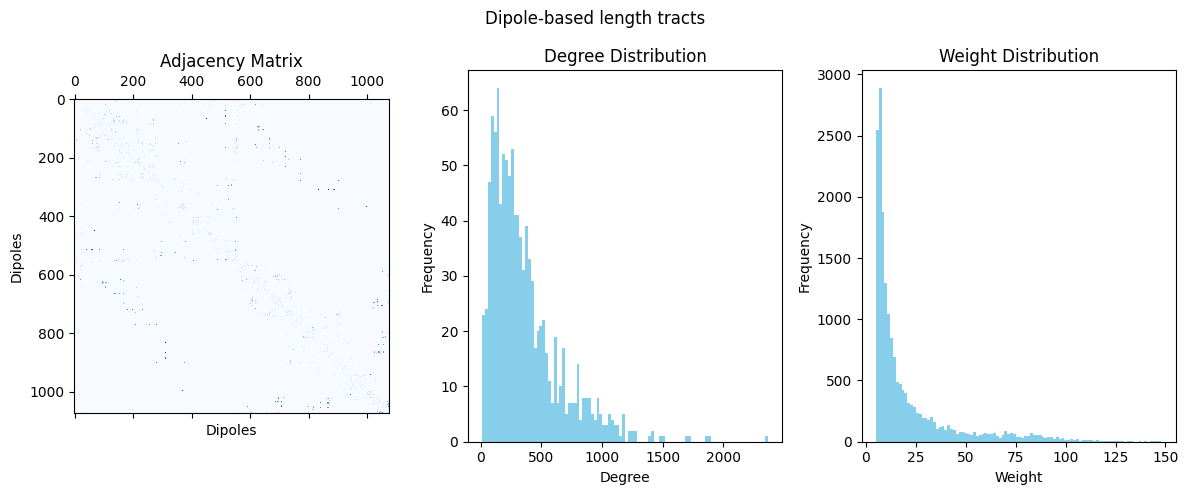

In [12]:
# find closest source to streamline endpoints
kd_tree      = sp.spatial.cKDTree(pos)
_, start_idx = kd_tree.query(starts)
_, end_idx   = kd_tree.query(ends)

# create sc matrix
sc_lengths = mm.utils.build_connectivity_matrix(start_idx, end_idx, num_dipoles=len(pos), w=lengths)
sc_weights = mm.utils.build_connectivity_matrix(start_idx, end_idx, num_dipoles=len(pos))

# define neighbor weights
array = sc_weights[np.triu_indices(sc_weights.shape[0], k=1)]
ngh_w = np.percentile(array[array>0], 99)

# visualization
viz = sc_lengths[idx][:,idx]                           
print_sc_summary(sc_lengths)

# plot
mm.viz.plot_connectome(viz, nonzero=True, name="Dipole-based length tracts")

Number of nodes: 1074
Total number of connections: 9155.0 (sparsity = 0.0159%)
Minimum (non-zero) weight: 1.0
Maximum weight: 239.0
Number of isolated nodes: 3 (ratio = 0.279)%


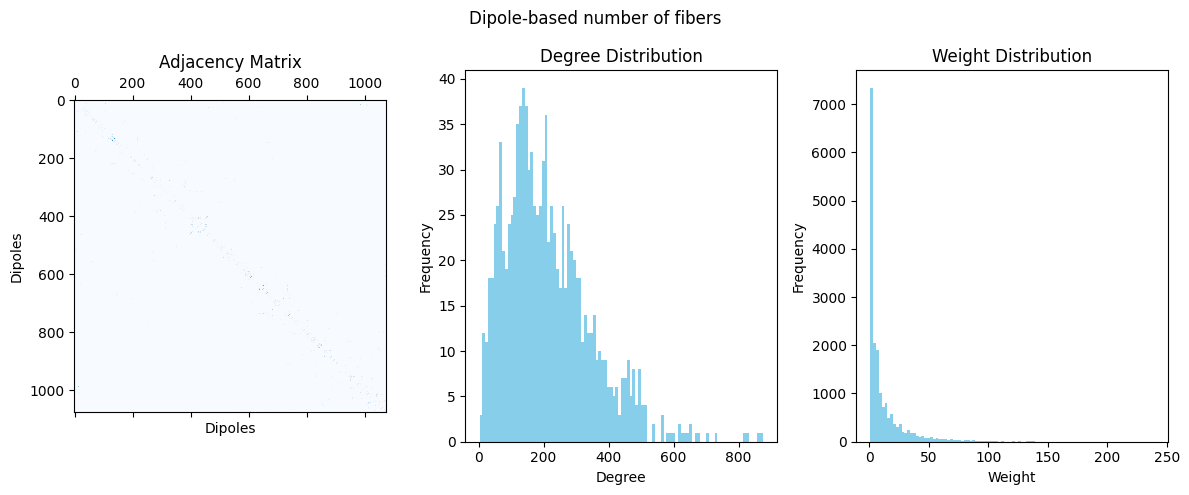

In [13]:
# visualization #
viz = sc_weights[idx][:,idx]                           
print_sc_summary(sc_weights)

# plot
mm.viz.plot_connectome(viz, nonzero=True, name="Dipole-based number of fibers")

The connectivity matrix appears sparse, primarily because it contains a large number of nodes. As a result, individual entries in the adjacency matrix are too small to be visible without zooming in. <br>

A more concerning issue is that some dipoles show no connections. This may be due to streamline endpoints being localized primarily within the gyri (as shown in the first 3D plot), which reduces the likelihood of forming connections with dipoles located in the sulci. <br>

Additionally, we currently assume that each streamline has a single, well-defined endpoint. However, this assumption oversimplifies reality—streamlines are composed of multiple nerve fibers that may terminate in different locations. This limitation becomes significant when analyzing high-resolution connectomes and should not be overlooked. <br>

In the following section, we implement the solutions proposed by Sina Mansour et al. (2020) to address these challenges in high-resolution connectome construction.

## 3. Smooth the result

The endpoints of streamlines are usually connected to multiple neurons. If the spacing between dipoles is very small, than the streamlines are most likely originating/terminating in multiple dipoles. To incorporate this in our connectomes, we can smooth the endpoints of streamlines with a gaussian kernel of approximately 2 mm (methodology described in [Sina Mansour et. al (2020)](https://www.sciencedirect.com/science/article/pii/S1053811920311800?via%3Dihub#sec0035)). Distances are to be understood as geodesic distances on the brain surface. <br>
🚨 Only recommended if dipole spacing is smaller than 2 mm 🚨<br>

📥 **<font color=pink>Inputs</font>**

- `sc`: Structural connectome

📥 **<font color=pink>Outputs</font>**

- `smooth_sc`: Smoothed structural connectome

🎚️ **<font color=pink>Smoothing</font>**:
- `dmax`: Neighborhood width.

In [10]:
import sklearn

def smooth_connectome(conn, kernel):
    """
    Smoothen connectome according to Sina Mansour et. al (2020)

    Parameters
    ----------
    conn: np.ndarray (N,N)
        Connectome.

    geodist: sp.sparse.csr (N, N)
        Geodesic distances between nodes.

    dmax: float
        Maximum neigborhood distance.

    fwhm: float
        Full width half maximum. 

    epsilon: float
        Smoothing radius parameter.

    dim:
        Smoothing dimensionality (surface is 2D)
    """
    # define incidence matrices
    indices = np.argwhere(conn>0)
    n, s    = len(conn), len(indices)
    M1, M2  = np.zeros((n,s)), np.zeros((n,s))

    for i, j in enumerate(indices):
        M1[j[0], i] = np.sqrt(conn[j[0],j[1]])
        M2[j[1], i] = np.sqrt(conn[j[1],j[0]])

    # smooth incidence
    M1s = (kernel.T @ M1)
    M2s = (kernel.T @ M2)

    # compute smoothed structural connectome
    sc = (M1s @ M2s.T) + (M2s @ M1s.T)
    sc = (sc + sc.T)/2
    np.fill_diagonal(sc, 0)

    return sc

def gaussian_kernel(geodist, fwhm, epsilon, dim):
    """
    Create Gaussian kernels for connectome smoothing.

    Parameters
    ----------
    geodist: sp.sparse.csr
        Geodesic distances between nodes.

    fwhm: float
        Full width half maximum. 

    epsilon: float
        Smoothing radius parameter.

    dim:
        Smoothing dimensionality (surface is 2D)

    Returns
    ------- 
    gaussian: sp.sparse.csr (N, N)
        Gaussian kernel for each node. The kernel distributes a weight arriving at node i between its neighbors.
    """
    # gaussian variance
    sigma = fwhm / np.sqrt(8*np.log(2))

    # maximum smoothing distance
    #max_smoothing_distance = sigma * (-sp.stats.norm.ppf((1-(1-epsilon)**(1/dim)) /1))
    max_smoothing_distance = sigma * (-2 * np.log(epsilon)) ** (1/dim)
    geodist[geodist>max_smoothing_distance] = 0
    geodist.eliminate_zeros()

    # Smoothing kernel for each node
    gaussian = -(geodist**2/(2*sigma**2))
    np.exp(gaussian.data, out=gaussian.data)
    gaussian += sp.sparse.eye(gaussian.shape[0], dtype=gaussian.dtype, format="csr")
    gaussian /= sp.sparse.linalg.norm(gaussian, ord=1, axis=1)[:, None]
    gaussian = sklearn.preprocessing.normalize(gaussian, norm="l1")     # sums to 1

    return gaussian

def unit_kernel(geodist, max_distance):
    """
    Create unit kernel for connectome smoothing.

    Parameters
    ----------
    geodist: sp.sparse.csr
        Geodesic distances between nodes.

    max_distance:
        Maximum width in [mm] of kernel.

    Returns
    -------
    unit_kernel: sp.sparse.csr (N,N)
        Unit kernel. The kernel of a node of interest is 1 for every neighbor node,
        meaning it is below `max_distance` from the node of interest.
    """
    # apply maximum smoothing distance
    geodist[geodist>max_distance] = 0
    geodist.eliminate_zeros()

    unit_kernel = geodist > 0      
    unit_kernel.setdiag(1)   # kernel is 1 if neighborhood else 0

    return unit_kernel

#### ⚙️ **<font color=green>Smooth weight connectivity according to Sina Mansour et. al (2020)</font>**

Number of nodes: 4961
Total number of connections: 184683.0 (sparsity = 0.015%)
Minimum (non-zero) weight: 9.999944686889647
Maximum weight: 2123.321258544922
Number of isolated nodes: 2 (ratio = 0.0403)%


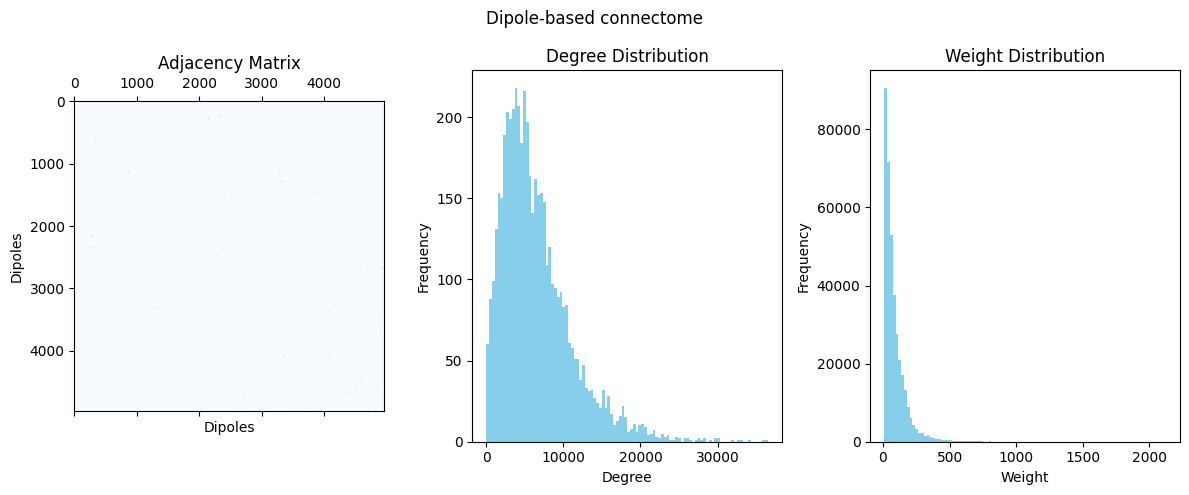

In [21]:
################## Parameters ##################
fwhm = 5            # [mm] ~ maximum width will be approximately the same
epsilon = 0.01
dim = 2
################################################

sigma = fwhm / np.sqrt(8*np.log(2))
max_distance = sigma * (-2 * np.log(epsilon)) ** (1/dim)

geodist         = mm.utils.get_geodist(data["src"])*1000    # in [mm]
gaussian_kernel = gaussian_kernel(geodist, fwhm, epsilon, dim)
unit_kernel     = unit_kernel(geodist, max_distance)

sc_lengths_smooth = smooth_connectome(sc_lengths, unit_kernel)
sc_weights_smooth = smooth_connectome(sc_weights, gaussian_kernel)

# visualization #
viz = sc_lengths_smooth[idx][:,idx]                           
print_sc_summary(sc_lengths_smooth)

# plot
mm.viz.plot_connectome(viz, nonzero=True, name="Dipole-based connectome")

In [ ]:
# visualization #
viz = sc_weights_smooth[idx][:,idx]                           
print_sc_summary(sc_weights_smooth)

# plot
mm.viz.plot_connectome(viz, nonzero=True, name="Dipole-based connectome")

In [22]:
np.diagonal(M@M.T)

array([2., 3., 6., 1., 9., 1., 4.])

#### ⚙️ **<font color=green>Smooth length connectivity with similar max width</font>**

In [ ]:
def share_connectivity(conn, geodist, max_width):
    """
    Share streamline with neighborhood arrival point.
    Difference, between share and smooth is that share will apply same weight to all neighborhood whereas smooth will
    distribute the weigth according to a spatial gaussian kernel.

    Parameters
    ----------
    conn: np.ndarray (N,N)
        Connectome

    max_width: float
        Maximum distance [mm] to share connection.

    Return
    ------
    share_sc: np.ndarray (N,N)
        Connectome sharing endpoint neighborhood.
    """

    neighborhood = geodist > 0      
    np.fill_diagonal(neighborhood, 1)   # kernel is 1 if neighborhood else 0

    # define incidence matrices
    indices = np.argwhere(sc_lengths>0)
    n, s    = data["src"][0]["nuse"] + data["src"][1]["nuse"], len(indices)
    M1, M2  = np.zeros((n,s)), np.zeros((n,s))

    for i, j in enumerate(indices):
        M1[j[0],i] = 1
        M2[j[1],i] = 1

    # smooth incidence
    M1s = (neighborhood.T @ M1)
    M2s = (neighborhood.T @ M2)

    # compute smooth structural connectome
    smooth_sc = (M1s @ M2s.T) + (M2s @ M1s.T)
    smooth_sc = (smooth_sc + smooth_sc.T)/2
    np.fill_diagonal(smooth_sc, 0)

    return smooth_sc

Number of nodes: 1545
Total number of connections: 21262.0 (sparsity = 0.0178%)
Minimum (non-zero) weight: 2.0
Maximum weight: 58.0
Number of isolated nodes: 193 (ratio = 12.5)%


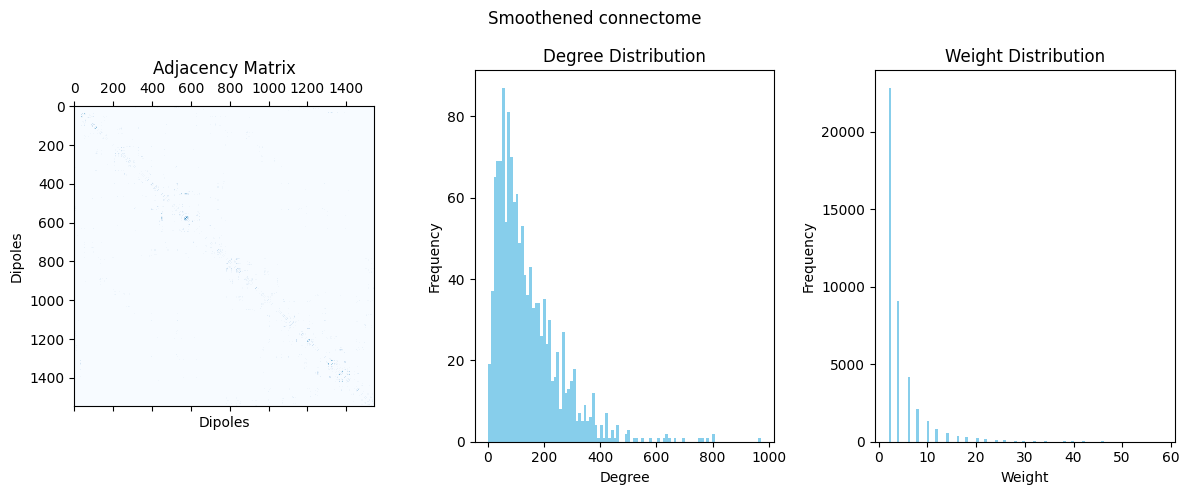

In [ ]:
################ Parameters ###################
dmax = 10
###############################################

# source geodesic distances
geodist = mm.utils.get_geodist(data["src"])*1000    # in [mm]
geodist[geodist>dmax] = 0
geodist.eliminate_zeros()

neighborhood = geodist > 0

# define incidence matrices
indices = np.argwhere(sc_lengths>0)
n, s    = data["src"][0]["nuse"] + data["src"][1]["nuse"], len(indices)
M1, M2  = np.zeros((n,s)), np.zeros((n,s))

for i, j in enumerate(indices):
    M1[j[0],i] = 1
    M2[j[1],i] = 1

# smooth incidence
M1s = (neighborhood.T @ M1)
M2s = (neighborhood.T @ M2)

# compute smooth structural connectome
smooth_sc = (M1s @ M2s.T) + (M2s @ M1s.T)
smooth_sc = (smooth_sc + smooth_sc.T)/2
np.fill_diagonal(smooth_sc, 0)

# visualization # 

# sort by parcellation labels
viz = smooth_sc[idx][:,idx]
print_sc_summary(smooth_sc)

mm.viz.plot_connectome(viz, nonzero=True, name="Smoothened connectome")

## 4. Add local neighbor connections

Tractography reveals the pathways within the white matter, but it is also understood that neurons communicate with their neighbors through the gray matter. To simulate this interaction, we artificially introduce connections between neighboring dipoles. Distance to measure closest neighbors is the geodesic distance on the surface.

📥 **<font color=pink>Inputs</font>**

- `src`: Source space – Contains geodesic distances between dipoles
- `smooth_sc`: Smoothed structural connectome

📥 **<font color=pink>Outputs</font>**

- `whole_sc`: Completed structural connectome.

🎚️ **<font color=pink>Geometry</font>**:
- `dmax`: Maximum distance in [mm] at which to connect a neighbor.

Number of nodes: 1074
Total number of connections: 9373.0 (sparsity = 0.0163%)
Minimum (non-zero) weight: 1.0744423866271973
Maximum weight: 147.99996948242188
Number of isolated nodes: 0 (ratio = 0.0)%


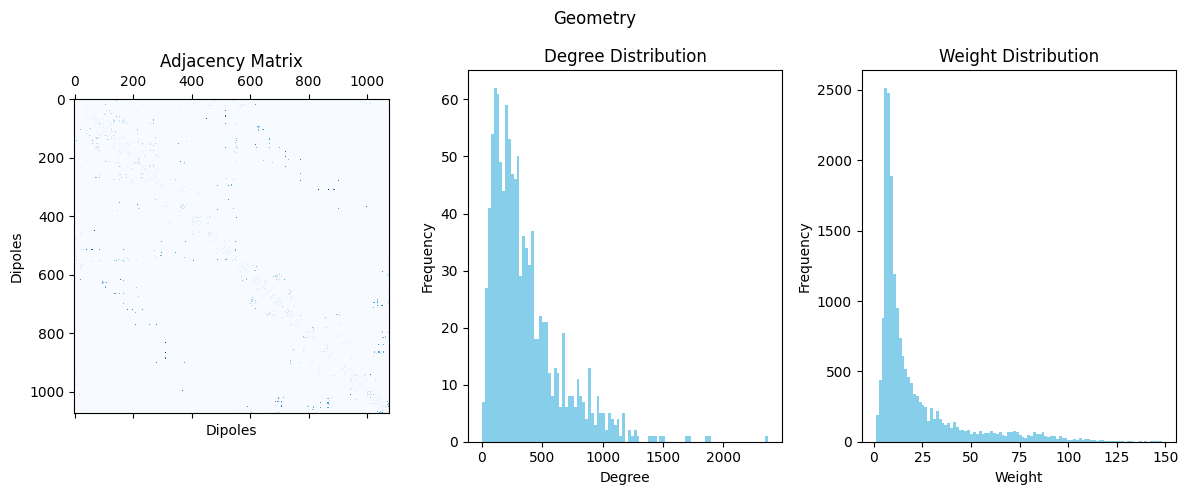

In [14]:
################ Parameters ################
dmax = 10
############################################

# add geometry on length connectome
geom_lengths = mm.utils.build_geometry(data["src"], dmax=dmax)
geom_idx = np.argwhere(geom_lengths > 0)

geom_sc_lengths = sc_lengths.copy()
geom_sc_lengths[geom_idx[:,0], geom_idx[:,1]] = geom_lengths[geom_idx[:,0], geom_idx[:,1]]

# add geometry on weigth connectome
geom_weights = (geom_lengths > 0).astype(int) * ngh_w
geom_sc_weights = sc_weights.copy()
geom_sc_weights[geom_idx[:,0], geom_idx[:,1]] = geom_weights[geom_idx[:,0], geom_idx[:,1]]


# sort by parcellation labels
viz = geom_sc_lengths[idx][:,idx]
print_sc_summary(geom_sc_lengths)

mm.viz.plot_connectome(viz, name="Geometry", nonzero=True)

Number of nodes: 1074
Total number of connections: 9373.0 (sparsity = 0.0163%)
Minimum (non-zero) weight: 1.0
Maximum weight: 239.0
Number of isolated nodes: 0 (ratio = 0.0)%


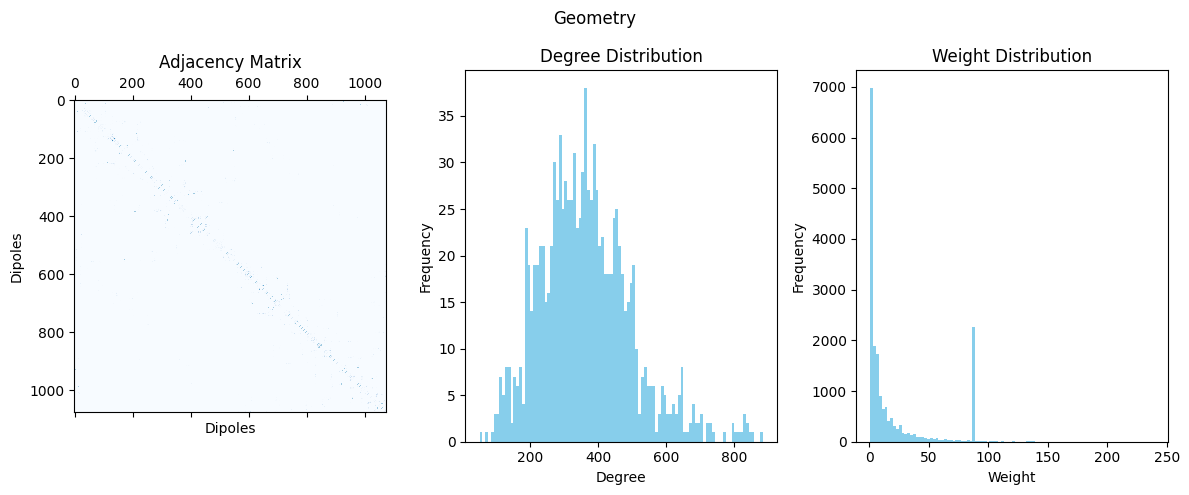

In [15]:
# sort by parcellation labels
viz = geom_sc_weights[idx][:,idx]
print_sc_summary(geom_sc_weights)

mm.viz.plot_connectome(viz, name="Geometry", nonzero=True)

The geometry barely adds new connections, we add it here to make sure it is present.

## 5. Assign informative weights

The connectome should reflect the constraints governing the flow of functional brain activity. Up to Section 3, the connectome was weighted based on the number of streamlines connecting each pair of regions. While this approach might naively suggest the potential capacity for information transfer between regions, there is currently no conclusive evidence supporting this assumption. <br>

In Section 4, we introduced local neighbor connections that are not informed by tract counts, making streamline-based weighting inconsistent. As a result, we binarized the connectivity from that point onward. <br>

An alternative approach is to incorporate **delays** on the edges, which would represent the speed at which information can flow between nodes. There is empirical evidence suggesting that signal delay is roughly proportional to the length of white matter tracts. Moreover, recent research indicates that incorporating conduction delays—rather than weights—can more effectively explain patterns observed in functional brain activity. <br>

Based on this, we propose using **fiber length** along white matter tracts and **geodesic distances** for neighboring (gray matter) connections as proxies for transmission delays, given that direct measurements of these delays are not available. <br>

#### ⚙️ **<font color=green>Assign distance weights</font>**

## 6. Connectome Spectrum Transform

The CST is simply the Fourier Graph Transform of the connectome. The harmonics (or eignevectors) of this transform are characteristic of the connectome.

📥 **<font color=pink>Inputs</font>**

- `whole_sc`: Final connectome

📥 **<font color=pink>Outputs</font>**

- `cst`: Connectome spectrum transform
- `eig`: Eigenvalues

In [16]:
coords = mm.utils.get_src_position(data["src"])

G = pygsp.graphs.Graph(geom_sc_lengths, lap_type="normalized", coords=coords)
G.compute_fourier_basis()

cst_lengths = G.U.T
eig_lengths = G.e

G = pygsp.graphs.Graph(geom_sc_weights, lap_type="normalized", coords=coords)
G.compute_fourier_basis()

cst_weights = G.U.T
eig_lengths = G.e

🌟 **Visualize harmonics**

In [17]:
############## Parameters #############
cst = cst_lengths
#######################################

mm.viz.plot_harmonics(data["src"], cst).show()

Widget(value='<iframe src="http://localhost:44117/index.html?ui=P_0x73e844ad8590_1&reconnect=auto" class="pyvi…

#### 💾 Save the SC

In [ ]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from tractography for subject: {sub}")
np.save(folder/f"{sub}_sc-length-tracto.npy", geom_sc_lengths)
np.save(folder/f"{sub}_sc-weight-tracto.npy", geom_sc_weights)

Saving SC from tractography for subject: vepcon_sub-10


#### 💾 Save the CST

In [ ]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving CST from tractography for subject: {sub}")
np.save(folder/f"{sub}_cst.npy", cst_lengths)

print(f"Saving eigenvalues for subject: {sub}")
np.save(folder/f"{sub}_eig.npy", eig_lengths)

Saving CST from tractography for subject: vepcon_sub-10
Saving eigenvalues for subject: vepcon_sub-10


In [ ]:
np.load(allo)